# VSA, prior specificity, and perceptual closure

**Question:** How much prior structure is needed to complete an ambiguous drawing, without being told its category at test time? When does that structure invent contours instead?

This small experiment uses generated binary cartoons, learned priors, role/filler bindings, and iterative factor inference. It compares a VSA-compressed observation model with an exact pixel baseline. You can change the prior family, prior strength, visibility, noise, vector dimension, and factor vocabulary.

**Scope:** this is a controlled computational analogue, not a replication of the cow drawing experiment or a model validated on real Mooney photographs. The mask tells the model which pixels are unknown, information that a real two-tone image does not explicitly provide. Even the uniform condition has a supplied face/cartoon vocabulary. The experiment tests constraints *within* that vocabulary, not the emergence of semantic features from arbitrary vectors.

Run **Kernel → Restart Kernel and Run All Cells**. Ordinary NumPy/SciPy, Pillow, and Matplotlib are sufficient for the model; no downloads, GPU, or API key. Runtime is normally seconds to a few minutes. Editable implementation: `closure_model.py` and `vsa_inference.py` in this folder.

In [1]:
from pathlib import Path
import sys, csv, json, time
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "closure_model.py").exists():
    ROOT = ROOT / "vsa_gestalt_closure"
if not (ROOT / "closure_model.py").exists():
    raise FileNotFoundError("Open this notebook from its folder or its parent workspace.")
sys.path.insert(0, str(ROOT))
from closure_model import *
from vsa_inference import PixelVSA, FactorVSA, posterior, mean_field, factor_marginals, entropy

OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
START = time.perf_counter()

## 1. Knobs to change first

`PRIOR_STRENGTH = 0` removes the learned prior but keeps the same candidate vocabulary. `MESSAGE_DIM` controls the vector dimension of **feature messages**; `VSA_DIM` controls compression of **image evidence**. Changing dimension does not change the number of candidate drawings. Encoding 2–3 candidate feature scores into a larger vector is expansion, not compression; it tests associative transmission and cross-talk.

The demo category below selects a stimulus for display, not a label passed into inference. The main benchmark samples all three categories and never passes its true labels to the model. Noise is independent pixel flips on the visible region; the model receives the specified noise rate.

In [2]:
SEED = 7
IMAGE_SIZE = 40
VSA_DIM = 512
MESSAGE_DIM = 64
FLIP_PROBABILITY = 0.05     # keep between 0 and .5 for useful positive evidence
N_TRAIN_PER_CLASS = 250
EXEMPLAR_PRECISION = 2.5    # larger = tighter memory of training combinations
PRIOR_STRENGTH = 1.0

DEMO_CATEGORY = 0          # 0 cow-like, 1 cat-like, 2 human-like (stimulus selection only)
DEMO_VISIBILITY = .30
DEMO_MASK = "top"         # "top" hides the nose; "blocks" gives random visible patches
DEMO_SEED = 37

VISIBILITIES = (.05, .10, .20)
TRIALS_PER_VISIBILITY = 9  # raise to 90+ for a less noisy exploratory comparison
STRENGTHS = (0., .5, 1., 2., 4.)
MF_SWEEPS = 25

## 2. What is known, learned, and withheld?

There are six discrete factors: head shape, ear shape, eye spacing, nose shape, layout, and contour closure. The full product contains **486** possible drawings, including open outlines and scrambled layouts. Every condition uses exactly this vocabulary and the same renderer.

Training and test **combinations** are split before drawing examples. Priors are learned from separate synthetic training configurations; their category labels are available during training. No test configuration is a training exemplar. The renderer still includes the held-out combinations, just as a compositional model can represent new combinations of known primitives. This is not generalization to unseen primitive types.

| Prior | Constraint supplied |
|---|---|
| Uniform vocabulary | No learned preferences among the 486 configurations |
| Layout + closure | Pooled training frequencies of aligned/lowered/scrambled layout and closed/open outline; no morphological category preferences |
| Latent categories | Learned mixture of factor distributions; category is not supplied at test |
| Training exemplars | Smooth Hamming-distance neighborhoods around training configurations |

These are **different prior families, not a mathematically nested specificity ladder**. Their entropy and strength also matter. The generic condition learns a preference for closed outlines; it does not learn local contour continuation from scratch. The cartoons are defined by the supplied grammar, so even the uniform model can complete parts.

486 candidate configurations; 364 training-eligible; 122 held out; 750 training draws.

Prior at strength 1:               entropy (nats)    effective states exp(H)
Uniform vocabulary                  6.186                486.0
Layout + closure                    5.448                232.3
Latent categories                   5.000                148.4
Training exemplars                  5.448                232.3


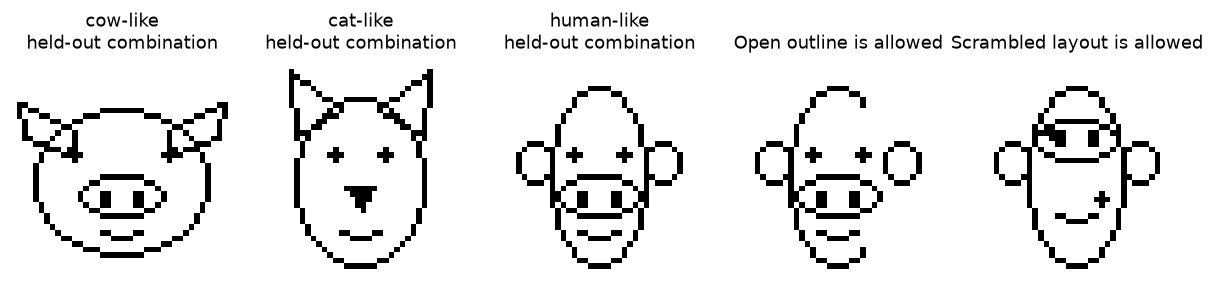

In [3]:
library = make_library(size=IMAGE_SIZE, seed=SEED)
training_ids, training_labels = sample_training(library, N_TRAIN_PER_CLASS, seed=SEED+4)
bank = fit_priors(library, training_ids, training_labels,
                  exemplar_precision=EXEMPLAR_PRECISION)
encoder = PixelVSA(IMAGE_SIZE, dim=VSA_DIM, seed=SEED+10)
factor_vsa = FactorVSA(CARDINALITIES, dim=MESSAGE_DIM, seed=SEED+20)
assert set(training_ids).isdisjoint(set(library.test_ids))
print(f"{len(library.states)} candidate configurations; {len(library.train_ids)} training-eligible; "
      f"{len(library.test_ids)} held out; {len(training_ids)} training draws.")
print("\nPrior at strength 1:               entropy (nats)    effective states exp(H)")
for name in PRIOR_NAMES:
    h = float(entropy(np.exp(bank.logpriors[name])))
    print(f"{PRIOR_LABELS[name]:30s} {h:10.3f} {np.exp(h):20.1f}")

fig, axes = plt.subplots(1, 5, figsize=(11, 2.7))
for c in range(3):
    k = int(library.test_ids[np.argmax(library.teacher_logp[c, library.test_ids])])
    show_completion(axes[c], library.images[k], CLASS_NAMES[c] + "\nheld-out combination")
open_state = library.states[k].copy(); open_state[5] = 1
scrambled_state = library.states[k].copy(); scrambled_state[4] = 2
show_completion(axes[3], render_state(open_state, IMAGE_SIZE), "Open outline is allowed")
show_completion(axes[4], render_state(scrambled_state, IMAGE_SIZE), "Scrambled layout is allowed")
fig.tight_layout()
plt.show()

## 3. The bridge from pixels to factors

We cannot manufacture an observation vector by binding the true hidden shape labels: that would give away the answer. Instead, a candidate factor configuration \(z\) generates an image \(R(z)\), which is compared only with the visible pixels \(y,M\).

For binary images with independent flip probability \(p\), the exact pixel log likelihood, up to a constant common to all candidates, is

\[
\ell(z)=-\log\frac{1-p}{p}\,\|M\odot(y-R(z))\|_2^2.
\]

The VSA image representation binds a pixel role, an x-location code, and a y-location code, then superposes pixels:

\[
\phi_{xy}=\frac{r_{\rm pixel}\odot X_x\odot Y_y}{\sqrt D},\qquad
H(I,M)=\sum_{xy}M_{xy}I_{xy}\phi_{xy}.
\]

The VSA backend substitutes \(\|H(y,M)-H(R(z),M)\|^2\) for the pixel residual. Cross-talk makes this a **pseudo-likelihood**, not a guaranteed calibrated probability model. The exact pixel baseline isolates its distortion. The full squared distance is needed: cosine alone would discard stroke count and evidence magnitude.

The finite posterior is

\[
q(z)\propto\exp[\ell(z)+\alpha\log p_s(z)],
\]

where \(s\) is the prior family and \(\alpha\) its strength. All 486 states can be enumerated, giving a reference against which iterative updates can be checked.

Separately, latent parts use the multi-binding structure we discussed, for example
\[
h_{\rm nose}=r_{\rm nose}\odot f_{\rm nose\ shape}\odot f_{\rm layout},\quad
h_{\rm scene}=h_{\rm outline}+h_{\rm ears}+h_{\rm eyes}+h_{\rm nose}.
\]
The role keys and value codebooks are fixed. Inference selects their value indices. Random bipolar codes do not intrinsically know what a cow or a smooth contour is.

In [4]:
# Algebra sanity check only: this known state is NOT a test observation encoder.
toy_state = np.array([1, 2, 2, 2, 0, 0])
scene_code = factor_vsa.encode(toy_state, GROUPS)
residual = factor_vsa.unbind_factor(scene_code, toy_state, 3, "nose", GROUPS)
decoded_nose = factor_vsa.cleanup_factor(residual, 3)
print("Bound part groups:", GROUPS)
print("Known-state binding demo, decoded nose:", FACTOR_VALUES[3][decoded_nose])
print("This demonstrates binding/cleanup with crosstalk; it is not visual recognition.")

Bound part groups: {'outline': (0, 5), 'ears': (1,), 'eyes': (2, 4), 'nose': (3, 4)}
Known-state binding demo, decoded nose: muzzle
This demonstrates binding/cleanup with crosstalk; it is not visual recognition.


## 4. A before/after completion example, without a test category cue

Blue-gray regions are unknown; white pixels are observed background. The stimulus below is a typical held-out combination chosen for illustration. The repeated benchmark later samples independently and includes less typical states.

A **posterior mean** is a probabilistic drawing and may look blurry. A **MAP sketch** is one committed configuration; it hides alternative interpretations and is not necessarily more faithful. Compare both to copying only the observed fragments.

Condition                    hidden Brier  hidden recall  invented/FPR  visible error
Copy fragments                     0.1357          0.000         0.000          0.000
Uniform vocabulary                 0.0434          0.632         0.000          0.050
Layout + closure                   0.0296          0.671         0.008          0.050
Latent categories                  0.0183          0.711         0.000          0.050
Training exemplars                 0.0289          0.711         0.002          0.050


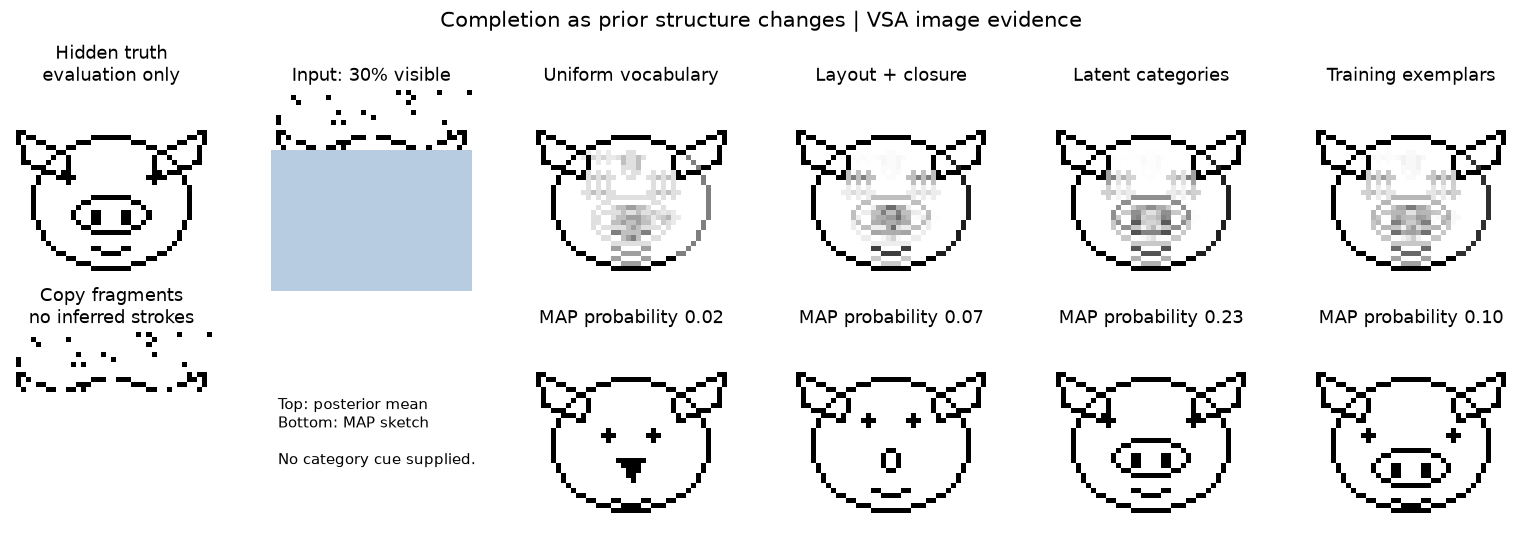

In [5]:
demo_id = int(library.test_ids[np.argmax(library.teacher_logp[DEMO_CATEGORY, library.test_ids])])
truth = library.images[demo_id]
rng = np.random.default_rng(DEMO_SEED)
if DEMO_MASK == "top":
    mask = np.broadcast_to(np.arange(IMAGE_SIZE)[:, None] < round(IMAGE_SIZE*DEMO_VISIBILITY),
                           truth.shape).copy()
elif DEMO_MASK == "blocks":
    mask = block_mask(IMAGE_SIZE, DEMO_VISIBILITY, rng)
else:
    raise ValueError("DEMO_MASK must be top or blocks")
observed = observe(truth, mask, FLIP_PROBABILITY, rng)
# Only the observed pixels and the mask enter the evidence function.
demo_scores = {backend: encoder.evidence_scores(library.images, observed, mask,
                        FLIP_PROBABILITY, backend) for backend in ("pixels", "vsa")}
demo_q = {name: posterior(demo_scores["vsa"], bank.logpriors[name], PRIOR_STRENGTH)
          for name in PRIOR_NAMES}
demo_predictions = {name: prediction(q, library.images) for name, q in demo_q.items()}

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
show_completion(axes[0, 0], truth, "Hidden truth\nevaluation only")
show_observation(axes[0, 1], observed, mask, f"Input: {mask.mean():.0%} visible")
show_completion(axes[1, 0], observed, "Copy fragments\nno inferred strokes")
axes[1, 1].axis("off")
axes[1, 1].text(.05, .5, "Top: posterior mean\nBottom: MAP sketch\n\nNo category cue supplied.",
                transform=axes[1, 1].transAxes, va="center")
for col, name in enumerate(PRIOR_NAMES, start=2):
    show_completion(axes[0, col], demo_predictions[name], PRIOR_LABELS[name])
    q = demo_q[name]
    show_completion(axes[1, col], library.images[np.argmax(q)], f"MAP probability {q.max():.2f}")
fig.suptitle("Completion as prior structure changes | VSA image evidence", fontsize=14)
fig.tight_layout()
fig.savefig(OUT / "completion_demo.png", dpi=160, bbox_inches="tight")
plt.show()

print(f"{'Condition':27s} {'hidden Brier':>13s} {'hidden recall':>14s} {'invented/FPR':>13s} {'visible error':>14s}")
for name, pred in [("Copy fragments", observed)] + [(PRIOR_LABELS[n], demo_predictions[n]) for n in PRIOR_NAMES]:
    metrics = completion_metrics(pred, truth, observed, mask)
    print(f"{name:27s} {metrics['hidden_brier']:13.4f} {metrics['hidden_recall']:14.3f} "
          f"{metrics['hidden_false_positive']:13.3f} {metrics['visible_error']:14.3f}")

## 5. Iterating individual factor estimates

The exact posterior above retains correlations among factors. A mean-field approximation instead stores a separate candidate distribution for each factor:
\[
q(z)=\prod_j q_j(z_j),\quad
q_j(k)\leftarrow\operatorname{softmax}_k\left(
\underbrace{E_{q_{-j}}[\ell(k,z_{-j})]}_{\text{bottom-up log message}}+
\underbrace{\alpha E_{q_{-j}}[\log p_s(k,z_{-j})]}_{\text{top-down log message}}
\right).
\]
These messages concern the same factor vocabulary. They are log scores, not arbitrary unit vectors interpreted directly as probabilities. Exact coordinate updates decrease variational free energy, but can settle into a local optimum and can discard multimodal alternatives.

The **VSA-message variant** superposes centered candidate scores in that factor's bipolar codebook, binds a channel role, then unbinds and reads candidate scores by dot product before updating. Thus VSA retrieval participates in the iterative feature estimates. Finite-dimensional cross-talk can change the updates; monotonic free energy is no longer guaranteed. This is a hybrid renderer/prior model with VSA message transmission, **not** direct resonator factorization of a raw image into semantic codes.

Dense mean-field total-variation distance from enumerated posterior: 0.0617
VSA mean-field total-variation distance from enumerated posterior: 0.2098


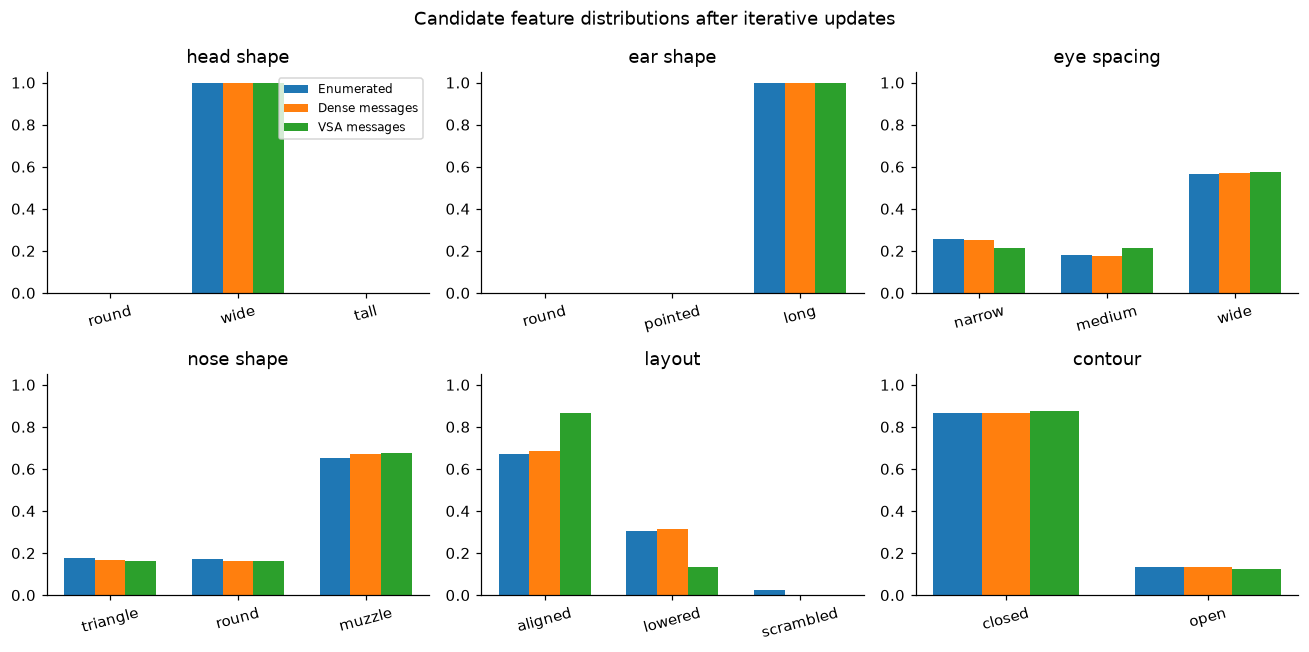

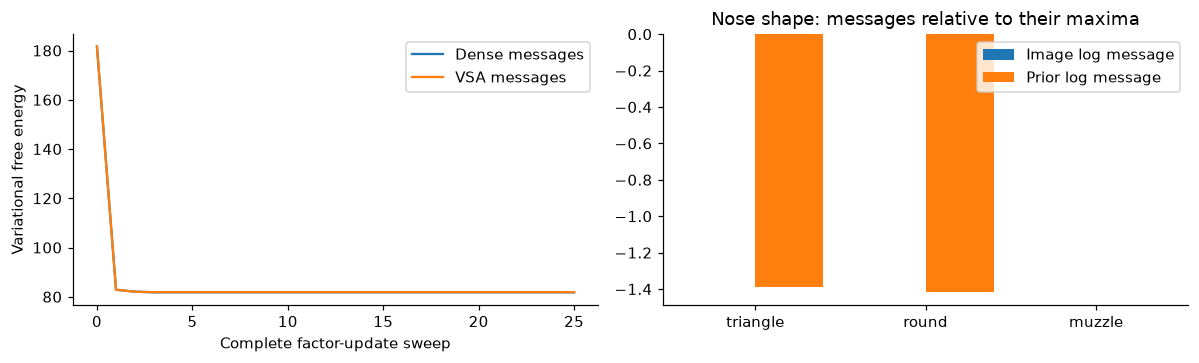

In [6]:
mf = mean_field(demo_scores["vsa"], bank.logpriors["category"], library.states,
                CARDINALITIES, strength=PRIOR_STRENGTH, sweeps=MF_SWEEPS, seed=SEED)
mf_vsa = mean_field(demo_scores["vsa"], bank.logpriors["category"], library.states,
                    CARDINALITIES, strength=PRIOR_STRENGTH, sweeps=MF_SWEEPS,
                    seed=SEED, message_vsa=factor_vsa)
exact_marginals = factor_marginals(demo_q["category"], library.states, CARDINALITIES)
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for j, ax in enumerate(axes.flat):
    x = np.arange(CARDINALITIES[j])
    ax.bar(x-.24, exact_marginals[j], width=.24, label="Enumerated")
    ax.bar(x, mf["marginals"][j], width=.24, label="Dense messages")
    ax.bar(x+.24, mf_vsa["marginals"][j], width=.24, label="VSA messages")
    ax.set_xticks(x, FACTOR_VALUES[j], rotation=15)
    ax.set_ylim(0, 1.05); ax.set_title(FACTOR_NAMES[j])
axes[0, 0].legend(fontsize=8)
fig.suptitle("Candidate feature distributions after iterative updates")
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for result, label in ((mf, "Dense messages"), (mf_vsa, "VSA messages")):
    axes[0].plot(result["free_energy"], label=label)
axes[0].set(xlabel="Complete factor-update sweep", ylabel="Variational free energy")
axes[0].legend()
j = 3  # nose shape; try another factor index
bottom = mf["bottom_messages"][j]; top = mf["top_messages"][j]
x = np.arange(CARDINALITIES[j])
axes[1].bar(x-.2, bottom-bottom.max(), width=.4, label="Image log message")
axes[1].bar(x+.2, top-top.max(), width=.4, label="Prior log message")
axes[1].set_xticks(x, FACTOR_VALUES[j]); axes[1].set_title("Nose shape: messages relative to their maxima")
axes[1].legend(); fig.tight_layout(); plt.show()
for label, q in (("Dense", mf["joint"]), ("VSA", mf_vsa["joint"])):
    print(label, "mean-field total-variation distance from enumerated posterior:",
          round(float(.5*np.abs(q-demo_q["category"]).sum()), 4))

## 6. Repeated no-cue experiment: specificity × strength × visibility

Every model sees the **same trials**. Hidden ground truth is used only for scoring. Test-time category labels are never passed to inference. Both likelihood backends use the same learned priors. The sweep is exploratory: if you select a setting from these results, create a fresh evaluation split before claiming generalization.

Metrics distinguish evidence preservation, helpful completion, and invention:

- **Hidden Brier:** squared error of edge probabilities in the hidden region; lower is better.
- **Hidden recall:** fraction of real hidden strokes drawn at probability ≥ .5.
- **Hidden false-positive rate:** fraction of hidden background pixels given a stroke at probability ≥ .5.
- **Visible error:** squared error against the supplied, possibly noisy visible pixels.

Because drawings are sparse, the copy/blank baseline can have a deceptively low Brier score and zero false positives while recovering no hidden strokes. Inspect all metrics together. Error bars are descriptive standard errors across trials, not evidence of a human perceptual effect.

Scored 27 held-out trials and 1107 condition/trial combinations.
Saved raw paired results to C:\NEU_172L\vsa_gestalt_closure\outputs\benchmark.csv


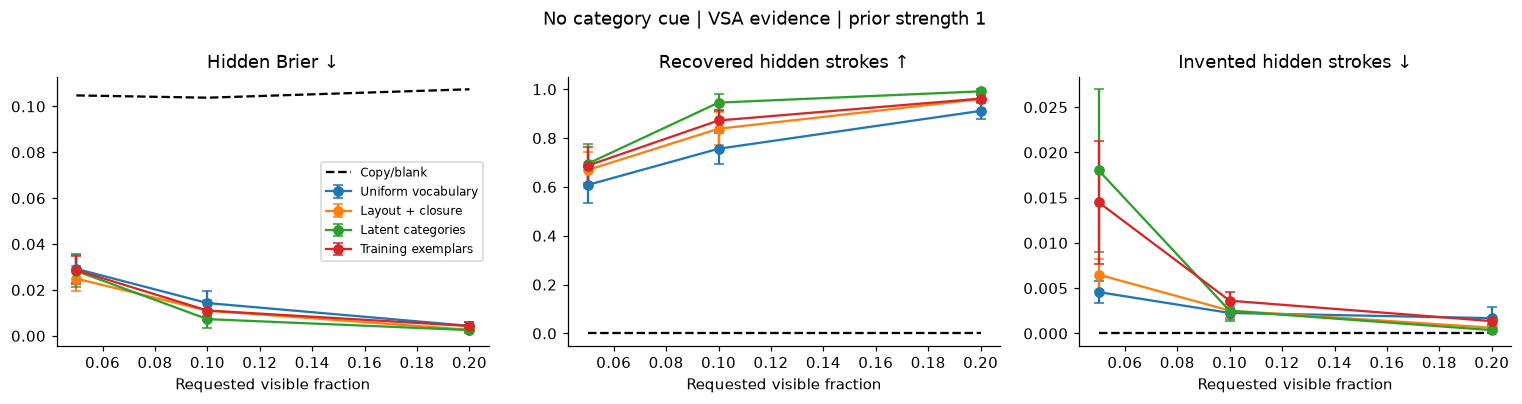

In [7]:
trials = sample_trials(library, TRIALS_PER_VISIBILITY, VISIBILITIES,
                       seed=SEED+100, flip_probability=FLIP_PROBABILITY)
rows = []
trial_scores = []
for trial_id, trial in enumerate(trials):
    scores = {backend: encoder.evidence_scores(library.images, trial["observed"], trial["mask"],
                       FLIP_PROBABILITY, backend) for backend in ("pixels", "vsa")}
    trial_scores.append(scores)
    base = completion_metrics(trial["observed"], trial["truth"], trial["observed"], trial["mask"])
    rows.append(dict(trial=trial_id, visibility=trial["visibility"], backend="copy",
                     prior="copy", strength=0., posterior_entropy=np.nan, **base))
    for backend in ("pixels", "vsa"):
        for name in PRIOR_NAMES:
            for strength in STRENGTHS:
                q = posterior(scores[backend], bank.logpriors[name], strength)
                pred = prediction(q, library.images)
                metrics = completion_metrics(pred, trial["truth"], trial["observed"], trial["mask"])
                rows.append(dict(trial=trial_id, visibility=trial["visibility"], backend=backend,
                                 prior=name, strength=strength, posterior_entropy=float(entropy(q)), **metrics))
with (OUT / "benchmark.csv").open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
    writer.writeheader(); writer.writerows(rows)
print(f"Scored {len(trials)} held-out trials and {len(rows)} condition/trial combinations.")
print("Saved raw paired results to", OUT / "benchmark.csv")

plot_strength = min(STRENGTHS, key=lambda x: abs(x-1.))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.7))
for ax, metric, title in zip(axes, ("hidden_brier", "hidden_recall", "hidden_false_positive"),
                            ("Hidden Brier ↓", "Recovered hidden strokes ↑", "Invented hidden strokes ↓")):
    for name in PRIOR_NAMES:
        values = [paired_summary(rows, metric, visibility=v, backend="vsa", prior=name,
                                  strength=plot_strength) for v in VISIBILITIES]
        ax.errorbar(VISIBILITIES, [a for a,b in values], yerr=[b for a,b in values],
                    marker="o", capsize=3, label=PRIOR_LABELS[name])
    baseline = [paired_summary(rows, metric, visibility=v, backend="copy")[0] for v in VISIBILITIES]
    ax.plot(VISIBILITIES, baseline, "k--", label="Copy/blank")
    ax.set(xlabel="Requested visible fraction", title=title)
axes[0].legend(fontsize=8)
fig.suptitle(f"No category cue | VSA evidence | prior strength {plot_strength:g}")
fig.tight_layout(); fig.savefig(OUT / "benchmark.png", dpi=160, bbox_inches="tight"); plt.show()

Exploratory settings with recall >= 0.5 and false-positive rate <= 0.03
at visibility 10%; confirm any selected setting on NEW trials:
[('uniform', 0.0, 0.7564452824290657, 0.0022620737417387896), ('uniform', 0.5, 0.7564452824290657, 0.0022620737417387896), ('uniform', 1.0, 0.7564452824290657, 0.0022620737417387896), ('uniform', 2.0, 0.7564452824290657, 0.0022620737417387896), ('uniform', 4.0, 0.7564452824290657, 0.0022620737417387896), ('generic', 0.0, 0.7564452824290657, 0.0022620737417387896), ('generic', 0.5, 0.8362810188512082, 0.00217567318877525), ('generic', 1.0, 0.8383135391764115, 0.0025212754006294063), ('generic', 2.0, 0.8383135391764115, 0.00303967871841064), ('generic', 4.0, 0.8383135391764115, 0.00303967871841064), ('category', 0.0, 0.7564452824290657, 0.0022620737417387896), ('category', 0.5, 0.9018546368906531, 0.0024929276696380107), ('category', 1.0, 0.9454460571986137, 0.0024933298444384613), ('category', 2.0, 0.9554012587914459, 0.002325993833728957), ('category', 

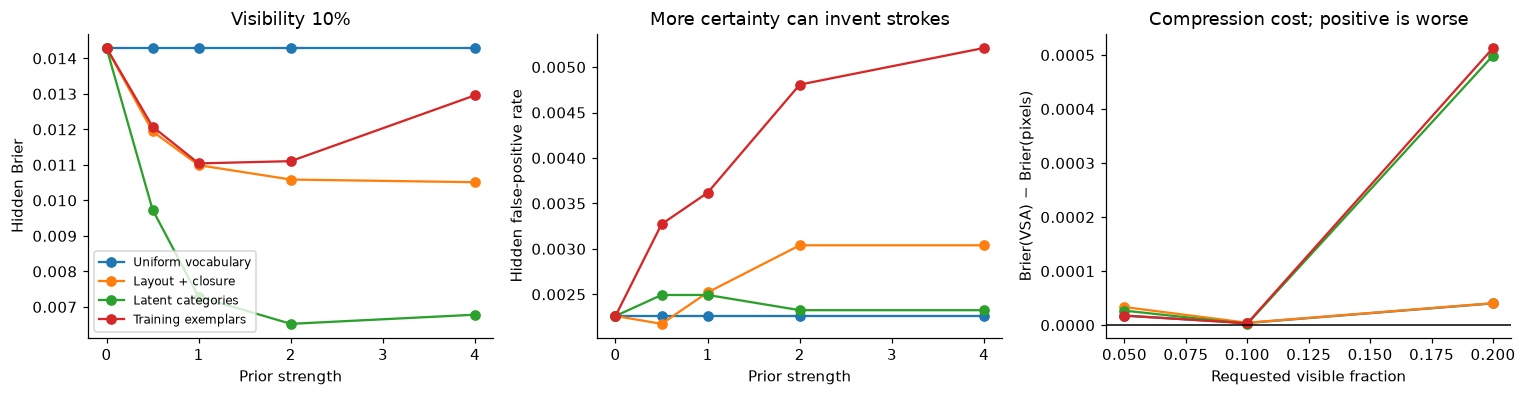

In [8]:
# Strength sweep and the exact-pixel control use the same underlying trials.
focus_visibility = VISIBILITIES[len(VISIBILITIES)//2]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.7))
for name in PRIOR_NAMES:
    for ax, metric in zip(axes[:2], ("hidden_brier", "hidden_false_positive")):
        vals = [paired_summary(rows, metric, visibility=focus_visibility, backend="vsa",
                               prior=name, strength=s)[0] for s in STRENGTHS]
        ax.plot(STRENGTHS, vals, "o-", label=PRIOR_LABELS[name])
    deltas = []
    for v in VISIBILITIES:
        a = paired_summary(rows, "hidden_brier", visibility=v, backend="vsa", prior=name, strength=plot_strength)[0]
        b = paired_summary(rows, "hidden_brier", visibility=v, backend="pixels", prior=name, strength=plot_strength)[0]
        deltas.append(a-b)
    axes[2].plot(VISIBILITIES, deltas, "o-", label=PRIOR_LABELS[name])
axes[0].set(xlabel="Prior strength", ylabel="Hidden Brier", title=f"Visibility {focus_visibility:.0%}")
axes[1].set(xlabel="Prior strength", ylabel="Hidden false-positive rate", title="More certainty can invent strokes")
axes[2].axhline(0, color="black", lw=1)
axes[2].set(xlabel="Requested visible fraction", ylabel="Brier(VSA) − Brier(pixels)", title="Compression cost; positive is worse")
axes[0].legend(fontsize=8); fig.tight_layout(); plt.show()

# A transparent screening criterion, not a universal threshold for Gestalt closure.
MIN_RECALL = .50
MAX_FALSE_POSITIVE = .03
print(f"Exploratory settings with recall >= {MIN_RECALL} and false-positive rate <= {MAX_FALSE_POSITIVE}")
print(f"at visibility {focus_visibility:.0%}; confirm any selected setting on NEW trials:")
passing = []
for name in PRIOR_NAMES:
    for strength in STRENGTHS:
        filters = dict(visibility=focus_visibility, backend="vsa", prior=name, strength=strength)
        rec = paired_summary(rows, "hidden_recall", **filters)[0]
        fp = paired_summary(rows, "hidden_false_positive", **filters)[0]
        if rec >= MIN_RECALL and fp <= MAX_FALSE_POSITIVE:
            passing.append((name, strength, rec, fp))
print(passing if passing else "None under these criteria. That is a valid experimental outcome.")

## 7. A genuinely absent contour and an information boundary

Create open and closed drawings that differ only at a hidden arc. Give the model identical visible pixels. With no external cue, its predictions **must be identical** for both possible truths. If it closes the arc, it succeeds on the closed case and invents a contour on the open case. This is an explicit limit on what can be recovered from the stimulus, not a bug to fix by forcing confidence.

Predicted stroke probability on the hidden distinguishing arc: 0.865
Brier if closed: 0.018174243805832
Brier if open: 0.7485504777477785


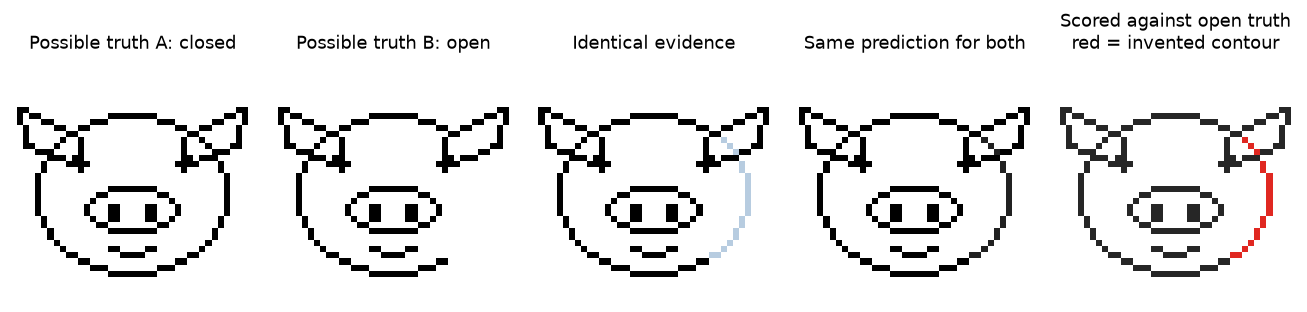

In [9]:
closed_state = library.states[demo_id].copy(); closed_state[5] = 0
open_state = closed_state.copy(); open_state[5] = 1
closed_truth = render_state(closed_state, IMAGE_SIZE)
open_truth = render_state(open_state, IMAGE_SIZE)
difference = closed_truth != open_truth
pair_mask = ~difference
pair_observed = np.where(pair_mask, closed_truth, 0).astype(np.float32)
assert np.array_equal(pair_observed, np.where(pair_mask, open_truth, 0))
ll_pair = encoder.evidence_scores(library.images, pair_observed, pair_mask, FLIP_PROBABILITY, "vsa")
q_pair = posterior(ll_pair, bank.logpriors["category"], PRIOR_STRENGTH)
pair_pred = prediction(q_pair, library.images)
fig, axes = plt.subplots(1, 5, figsize=(12, 2.7))
show_completion(axes[0], closed_truth, "Possible truth A: closed")
show_completion(axes[1], open_truth, "Possible truth B: open")
show_observation(axes[2], pair_observed, pair_mask, "Identical evidence")
show_completion(axes[3], pair_pred, "Same prediction for both")
axes[4].imshow(error_overlay(pair_pred, open_truth, pair_mask))
axes[4].set_title("Scored against open truth\nred = invented contour"); axes[4].axis("off")
fig.tight_layout(); fig.savefig(OUT / "open_contour_control.png", dpi=160, bbox_inches="tight"); plt.show()
print("Predicted stroke probability on the hidden distinguishing arc:", round(float(pair_pred[difference].mean()), 3))
print("Brier if closed:", completion_metrics(pair_pred, closed_truth, pair_observed, pair_mask)["hidden_brier"])
print("Brier if open:", completion_metrics(pair_pred, open_truth, pair_observed, pair_mask)["hidden_brier"])

## 8. Explicit correct/wrong cues and scrambled input controls

This section intentionally supplies category cues, approximating a before/after instruction manipulation. It is **excluded from the no-cue claim**. A category cue is the learned conditional distribution for that category, not a copy of the test drawing. Cue strength is a separate assumption: contradictory visible evidence can outweigh a weak cue.

The scrambled-layout example is in the hypothesis vocabulary, so the model can select it. The system has no general out-of-vocabulary rejection model: a confident answer to an arbitrary photograph would not establish recognition.

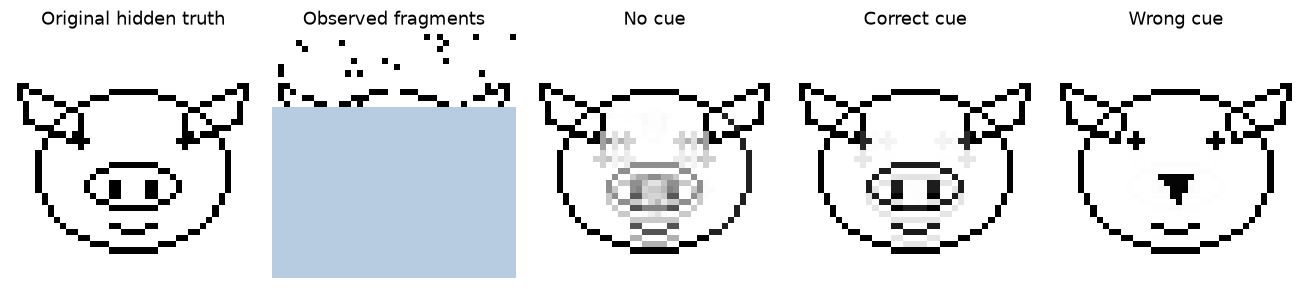

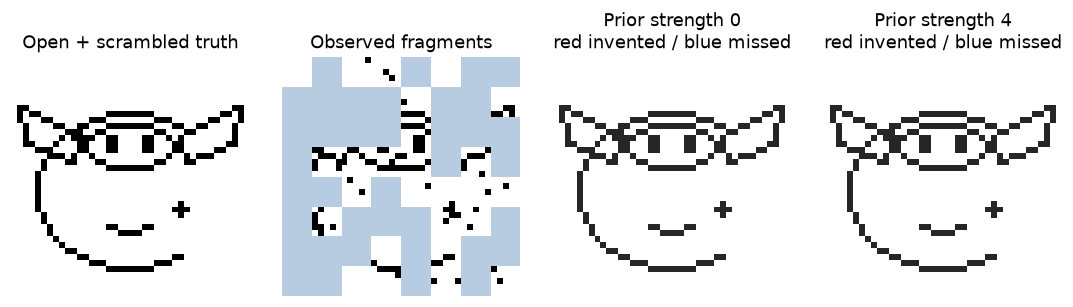

In [10]:
CUE_STRENGTH = 3.0
correct_cue = DEMO_CATEGORY
wrong_cue = (DEMO_CATEGORY + 1) % len(CLASS_NAMES)
cue_conditions = [("No cue", bank.logpriors["category"], PRIOR_STRENGTH),
                  ("Correct cue", bank.class_logp[correct_cue], CUE_STRENGTH),
                  ("Wrong cue", bank.class_logp[wrong_cue], CUE_STRENGTH)]
fig, axes = plt.subplots(1, 5, figsize=(12, 2.7))
show_completion(axes[0], truth, "Original hidden truth")
show_observation(axes[1], observed, mask)
for ax, (label, lp, strength) in zip(axes[2:], cue_conditions):
    q = posterior(demo_scores["vsa"], lp, strength)
    show_completion(ax, prediction(q, library.images), label)
fig.tight_layout(); fig.savefig(OUT / "cue_control.png", dpi=160, bbox_inches="tight"); plt.show()

negative_state = library.states[demo_id].copy(); negative_state[4] = 2; negative_state[5] = 1
negative = render_state(negative_state, IMAGE_SIZE)
neg_rng = np.random.default_rng(SEED+999)
negative_mask = block_mask(IMAGE_SIZE, .35, neg_rng)
negative_observed = observe(negative, negative_mask, FLIP_PROBABILITY, neg_rng)
negative_scores = encoder.evidence_scores(library.images, negative_observed, negative_mask, FLIP_PROBABILITY, "vsa")
fig, axes = plt.subplots(1, 4, figsize=(10, 2.7))
show_completion(axes[0], negative, "Open + scrambled truth")
show_observation(axes[1], negative_observed, negative_mask)
for ax, strength in zip(axes[2:], (0., 4.)):
    q = posterior(negative_scores, bank.logpriors["category"], strength)
    pred = prediction(q, library.images)
    ax.imshow(error_overlay(pred, negative, negative_mask)); ax.axis("off")
    ax.set_title(f"Prior strength {strength:g}\nred invented / blue missed")
fig.tight_layout(); plt.show()

## 9. Does VSA dimension change the result?

The small check below measures posterior distortion and hidden prediction error on the same trials at several dimensions and codebook seeds. A larger dimension reduces cross-talk on average; individual trials need not improve monotonically. This section isolates the image-evidence representation, while Section 5 tests VSA-encoded factor messages separately.

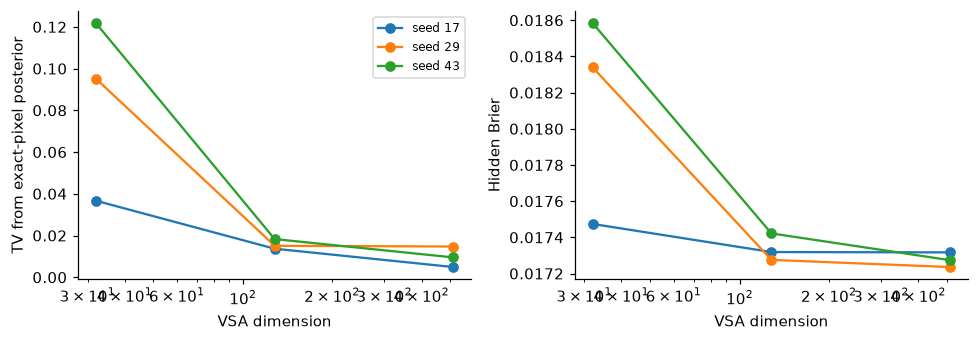

In [11]:
DIMENSIONS = (32, 128, 512)
CODEBOOK_SEEDS = (17, 29, 43)
DIMENSION_TRIALS = min(6, len(trials))
dimension_rows = []
for dim in DIMENSIONS:
    for code_seed in CODEBOOK_SEEDS:
        enc = PixelVSA(IMAGE_SIZE, dim, code_seed)
        for i, trial in enumerate(trials[:DIMENSION_TRIALS]):
            ll = enc.evidence_scores(library.images, trial["observed"], trial["mask"], FLIP_PROBABILITY, "vsa")
            q = posterior(ll, bank.logpriors["category"], PRIOR_STRENGTH)
            qp = posterior(trial_scores[i]["pixels"], bank.logpriors["category"], PRIOR_STRENGTH)
            m = completion_metrics(prediction(q, library.images), trial["truth"], trial["observed"], trial["mask"])
            dimension_rows.append(dict(dim=dim, seed=code_seed, trial=i,
                                       tv=float(.5*np.abs(q-qp).sum()), brier=m["hidden_brier"]))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, metric, ylabel in zip(axes, ("tv", "brier"), ("TV from exact-pixel posterior", "Hidden Brier")):
    for code_seed in CODEBOOK_SEEDS:
        vals = [np.mean([r[metric] for r in dimension_rows if r["dim"] == d and r["seed"] == code_seed]) for d in DIMENSIONS]
        ax.plot(DIMENSIONS, vals, "o-", label=f"seed {code_seed}")
    ax.set(xlabel="VSA dimension", ylabel=ylabel, xscale="log")
axes[0].legend(fontsize=8); fig.tight_layout(); plt.show()

## 10. Reading the result and extending it

Evidence for useful closure in this toy task would be better recovery of hidden strokes **without excessive invention**, on new combinations, with no category cue. Lower entropy alone is not success. If a strong prior improves ordinary cases but closes genuinely open contours, it demonstrates the completion/invention tradeoff in your proposed experiment.

Do not interpret a successful run as proof that VSA alone produces Gestalt organization. The supplied renderer, factor vocabulary, and learned priors supply the regularities. VSA supplies a compositional representation and, in the tested variants, compressed observations and vector-encoded feature messages. Exact enumeration and dense-message controls show what changes because of compression or approximate inference.

Useful next modifications:

1. Change `FACTOR_VALUES`, `render_state`, and `make_library` together to vary the specificity of the actual **feature vocabulary**, not just priors over fixed values. This is the next step toward your unrestricted-f-hat question.
2. Replace the generic layout/closure labels with local curvature and continuation factors. This would test whether low-level geometric constraints suffice before category priors are introduced.
3. Add translation, rotation, more part positions, non-face objects, and a reject/unknown model. The current fixed, centered canvas supplies substantial structure.
4. Learn the category prior without labels, then compare it with supervised training. The current model has no test label but does use labeled training categories.
5. Replace the known mask with a thresholded shaded renderer and a likelihood that marginalizes lighting/threshold. Real Mooney images are not simply incomplete line drawings.
6. For a real drawing study, distinguish perceptual change, memory, and deliberate drawing strategy. This notebook models inferred reconstructions, not the participant's intentions.

The original cow before/after drawing result is treated here as your reported motivation; this notebook does not verify its specific protocol or results. For Mooney stimuli and closure context, the primary paper [Schwiedrzik, Melloni & Schurger (2018)](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0200106) describes two-tone face stimuli, inversion and scrambling controls, and a publicly available stimulus set. Your [Mooney Face Test link](https://en.wikipedia.org/wiki/Mooney_Face_Test) was the starting reference. No external images are needed or downloaded by this notebook.

In [12]:
# Lightweight run checks; more comprehensive invariants are in test_closure_model.py.
assert set(training_ids).isdisjoint(set(library.test_ids))
assert all(np.isclose(q.sum(), 1) for q in demo_q.values())
assert np.all(np.diff(mf["free_energy"]) <= 1e-8)
changed_hidden = observed.copy(); changed_hidden[~mask] = 123.0
assert np.allclose(encoder.evidence_scores(library.images, changed_hidden, mask, FLIP_PROBABILITY, "vsa"),
                   demo_scores["vsa"])
assert np.array_equal(np.where(pair_mask, closed_truth, 0), np.where(pair_mask, open_truth, 0))
summary = {"candidates": len(library.states), "held_out_combinations": len(library.test_ids),
           "training_examples": len(training_ids), "benchmark_trials": len(trials),
           "vsa_dimension": VSA_DIM, "message_dimension": MESSAGE_DIM,
           "elapsed_seconds": round(time.perf_counter()-START, 2),
           "checks_passed": True,
           "scope": "synthetic known-mask closure analogue; not validated on Mooney photographs"}
(OUT / "run_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(json.dumps(summary, indent=2))

{
  "candidates": 486,
  "held_out_combinations": 122,
  "training_examples": 750,
  "benchmark_trials": 27,
  "vsa_dimension": 512,
  "message_dimension": 64,
  "elapsed_seconds": 8.61,
  "checks_passed": true,
  "scope": "synthetic known-mask closure analogue; not validated on Mooney photographs"
}
